# Hydroformylation Physics-Informed Transition Training

This notebook mirrors notebook 06 for the hydroformylation transition surrogate used in notebook 04. It trains a data-only one-step tanh model, sweeps physics penalty weights on the validation set, selects the best physics-informed transition model, and only then runs the NMPC optimization benchmark.

## Setup

In [1]:
from __future__ import annotations

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from pwlnet import PWLNet, PhysicsLoss, PhysicsSpec
from pwlnet.benchmarking.metrics import metrics_table
from pwlnet.processes.hydroformylation import (
    CONTROL_BOUNDS,
    CONTROL_DT_MIN,
    DT_RATE_LIMIT,
    CONTROL_NAMES,
    DT_MIN,
    HydroformylationParameters,
    IDX,
    INITIAL_STATE,
    N_STEPS,
    STATE_BOUNDS,
    STATE_NAMES,
    T_FINAL,
    make_transition_dataset,
    pressure_backoff,
    reachable_input_bounds,
    run_receding_horizon_nmpc,
    simulate_policy,
    step_state,
)
from pwlnet.utils.exceptions import SolverNotAvailableError

RANDOM_SEED = 2479085
rng = np.random.default_rng(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid")

input_names = ["tau", *STATE_NAMES, *CONTROL_NAMES]
input_bounds = [(0.0, 1.0), *map(tuple, STATE_BOUNDS), *map(tuple, CONTROL_BOUNDS)]
state_ranges = STATE_BOUNDS[:, 1] - STATE_BOUNDS[:, 0]
pd.DataFrame(input_bounds, index=input_names, columns=["lower", "upper"])

,lower,upper
tau,0.00,1.00
c_H2,0.00,0.60
c_CO,0.00,0.60
nC12en,0.00,1.20
iC12en,0.00,0.80
nC13al,0.00,0.90
nC12an,0.00,0.80
iC13al,0.00,0.80
p_H2,0.10,22.00
p_CO,0.10,22.00


## Transition Data

The supervised map is the same one-step transition used by notebook 04:

`[tau, x_k, T_k, u_k] -> x_{k+1}`.

The split is fixed so lambda selection and downstream optimization are reproducible.

In [2]:
DATA_CONFIG = dict(n_trajectories=160, rng=rng)
X, y = make_transition_dataset(**DATA_CONFIG)
perm = rng.permutation(len(X))
n_train = int(0.70 * len(perm))
n_val = int(0.15 * len(perm))
train_idx = perm[:n_train]
val_idx = perm[n_train : n_train + n_val]
test_idx = perm[n_train + n_val :]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"train={X_train.shape}, validation={X_val.shape}, test={X_test.shape}")
pd.DataFrame(y, columns=STATE_NAMES).describe().T

train=(1568, 12), validation=(336, 12), test=(336, 12)


,count,mean,std,min,25%,50%,75%,max
c_H2,2240.0,0.064887,0.013780,0.032660,0.054811,0.063474,0.073375,0.123259
c_CO,2240.0,0.114699,0.023398,0.060427,0.097499,0.112809,0.129193,0.211995
nC12en,2240.0,0.253800,0.257872,0.002297,0.023088,0.147306,0.453482,0.848424
iC12en,2240.0,0.246335,0.100411,0.036879,0.163875,0.259293,0.328802,0.425563
nC13al,2240.0,0.397520,0.150052,0.050331,0.285039,0.453440,0.517248,0.656353
nC12an,2240.0,0.038382,0.018456,0.003266,0.023852,0.039557,0.052291,0.079574
iC13al,2240.0,0.008407,0.004880,0.000513,0.004306,0.008243,0.011862,0.023508
p_H2,2240.0,11.513846,2.432747,5.835784,9.710731,11.336441,13.014952,21.877697
p_CO,2240.0,11.173329,2.238018,5.949727,9.528237,10.980722,12.573955,20.579666


## Physics Diagnostics

The transition physics checks are intentionally aligned with the control problem: output state bounds, next-step pressure-backoff safety, and monotonic accumulation of irreversible products. These diagnostics are also used by the lambda selection rule.

In [3]:
PRODUCT_MONOTONE_INDICES = [IDX["nC13al"], IDX["nC12an"], IDX["iC13al"]]


def hydro_physics_terms(X_eval, y_pred):
    X_eval = np.atleast_2d(np.asarray(X_eval, dtype=float))
    y_pred = np.atleast_2d(np.asarray(y_pred, dtype=float))
    lo = STATE_BOUNDS[:, 0]
    hi = STATE_BOUNDS[:, 1]
    scale = np.maximum(hi - lo, 1e-9)
    bound_violation = np.maximum(lo - y_pred, 0.0) + np.maximum(y_pred - hi, 0.0)
    t_next = X_eval[:, 0] * T_FINAL + CONTROL_DT_MIN
    p_limit = np.array([20.0 - pressure_backoff(float(t)) for t in t_next])
    pressure_violation = np.maximum(y_pred[:, IDX["p_H2"]] + y_pred[:, IDX["p_CO"]] - p_limit, 0.0)
    current_products = X_eval[:, 1 + np.asarray(PRODUCT_MONOTONE_INDICES)]
    next_products = y_pred[:, PRODUCT_MONOTONE_INDICES]
    monotone_violation = np.maximum(current_products - next_products, 0.0)
    return {
        "bounds_rmse": float(np.sqrt(np.mean(np.square(bound_violation / scale)))),
        "pressure_rmse": float(np.sqrt(np.mean(np.square(pressure_violation / 20.0)))),
        "monotonic_rmse": float(np.sqrt(np.mean(np.square(monotone_violation / scale[PRODUCT_MONOTONE_INDICES])))),
        "max_pressure_violation_bar": float(np.max(pressure_violation)),
        "max_bound_violation_scaled": float(np.max(bound_violation / scale)),
    }


def hydro_physics_score(X_eval, y_pred):
    terms = hydro_physics_terms(X_eval, y_pred)
    return float(terms["bounds_rmse"] + terms["pressure_rmse"] + terms["monotonic_rmse"])


def hydro_physics_report(name, X_eval, y_pred):
    terms = hydro_physics_terms(X_eval, y_pred)
    return {"model": name, **terms, "physics_score": hydro_physics_score(X_eval, y_pred)}

hydro_physics_report("exact transitions", X_test, y_test)

{'model': 'exact transitions',
 'bounds_rmse': 0.0,
 'pressure_rmse': 0.27108417921489214,
 'monotonic_rmse': 0.0,
 'max_pressure_violation_bar': 16.216709006017997,
 'max_bound_violation_scaled': 0.0,
 'physics_score': 0.27108417921489214}

## Data-Only Baseline

In [4]:
plain = PWLNet.train(
    X_train,
    y_train,
    hidden_layers=[32],
    activation="tanh",
    loss="mse",
    epochs=300,
    batch_size=128,
    validation_data=(X_val, y_val),
    early_stopping_patience=35,
    random_seed=RANDOM_SEED,
    verbose=0,
)

print(plain.summary())
print(f"Keras/core max prediction difference: {plain.trainer.equivalence_error_:.3e}")
plain_metrics = metrics_table({
    "plain train": (y_train, plain.predict(X_train)),
    "plain validation": (y_val, plain.predict(X_val)),
    "plain test": (y_test, plain.predict(X_test)),
})
plain_metrics

NetworkDefinition: 12 inputs -> 9 outputs, 2 layers, 32 hidden neurons, 713 parameters
layer   n_in  n_out activation   params
    0     12     32       tanh      416
    1     32      9     linear      297
Keras/core max prediction difference: 1.526e-06


,split,MAE,MSE,RMSE,R2,n_samples
0,plain train,0.026267,0.005274,0.072622,0.995780,1568
1,plain validation,0.029753,0.006596,0.081217,0.994851,336
2,plain test,0.026064,0.005083,0.071293,0.995166,336


## Physics-Informed Lambda Sweep

The hydroformylation physics-informed model uses the same architecture as the baseline and sweeps three penalty weights. The state bounds, pressure-backoff, and monotonic irreversible-product constraints are declared with the generic `PhysicsSpec` API.

```text
scaled data MSE
+ lambda_bounds * normalized state-bound violation
+ lambda_pressure * normalized pressure-backoff violation
+ lambda_monotonic * irreversible-product decrease violation
```

Selection is done before NMPC: keep candidates whose validation scaled data MSE is within `LAMBDA_SELECTION_DATA_TOLERANCE` of the best data fit, then choose the lowest validation physics score.

In [5]:
generic_transition_spec = PhysicsSpec(input_names=input_names, output_names=STATE_NAMES).box_bounds(
    {
        state_name: tuple(STATE_BOUNDS[state_idx])
        for state_idx, state_name in enumerate(STATE_NAMES)
    },
    normalize=True,
    name="bounds",
    loss="mse",
).backoff_relation(
    time_input="tau",
    time_scale=T_FINAL,
    time_offset=CONTROL_DT_MIN,
    breakpoints=[30.0, 55.0],
    backoffs=[1.3, 0.7, 0.0],
    outputs={"p_H2": 1.0, "p_CO": 1.0},
    limit=20.0,
    violation_scale=20.0,
    name="pressure",
    loss="mse",
)
generic_transition_spec.monotonic_outputs(
    [STATE_NAMES[idx] for idx in PRODUCT_MONOTONE_INDICES],
    direction="nondecreasing",
    violation_scale={
        STATE_NAMES[idx]: float(max(state_ranges[idx], 1e-9))
        for idx in PRODUCT_MONOTONE_INDICES
    },
    name_prefix="monotonic",
    loss="mse",
)
generic_transition_physics = generic_transition_spec.build()


class HydroformylationTransitionPhysics(PhysicsLoss):
    name = "hydroformylation_transition"
    input_dim = 1 + len(STATE_NAMES) + len(CONTROL_NAMES)
    output_dim = len(STATE_NAMES)
    default_weights = {"bounds": 0.0, "pressure": 0.0, "monotonic": 0.0}

    def __init__(self, generic_physics=generic_transition_physics):
        self.generic_physics = generic_physics

    def build_constants(self, tf):
        return {"generic": self.generic_physics.build_constants(tf)}

    def loss_terms(self, tf, x_orig, y_orig, constants):
        generic_terms = self.generic_physics.loss_terms(tf, x_orig, y_orig, constants["generic"])
        monotonic_terms = [
            value for key, value in generic_terms.items()
            if key.startswith("monotonic_")
        ]
        monotonic_loss = tf.add_n(monotonic_terms) / float(len(monotonic_terms))
        return {
            "bounds_loss": generic_terms["bounds_loss"],
            "pressure_loss": generic_terms["pressure_loss"],
            "monotonic_loss": monotonic_loss,
        }


In [6]:
LAMBDA_SWEEP_GRID = [
    {"bounds": bounds, "pressure": pressure, "monotonic": monotonic}
    for bounds in [0.10, 0.20]
    for pressure in [0.0]
    for monotonic in [0.10, 0.20]
]
LAMBDA_SELECTION_DATA_TOLERANCE = 0.10

lambda_sweep_models = {}
lambda_sweep_rows = []
for i, weights in enumerate(LAMBDA_SWEEP_GRID):
    candidate = PWLNet.train_physics_informed(
        X_train,
        y_train,
        hidden_layers=[32],
        activation="tanh",
        physics=HydroformylationTransitionPhysics(),
        physics_weights=weights,
        epochs=300,
        batch_size=128,
        validation_data=(X_val, y_val),
        early_stopping_patience=35,
        random_seed=RANDOM_SEED,
        verbose=0,
    )
    y_val_pred = candidate.predict(X_val)
    history = pd.DataFrame(candidate.trainer.history_)
    y_val_scaled = candidate.trainer.output_scaler_.transform(y_val)
    y_val_pred_scaled = candidate.trainer.output_scaler_.transform(y_val_pred)
    val_data_loss = float(np.mean(np.square(y_val_pred_scaled - y_val_scaled)))
    val_mse = float(np.mean(np.square(y_val_pred - y_val)))
    row = {
        "candidate": i,
        "lambda_bounds": weights["bounds"],
        "lambda_pressure": weights["pressure"],
        "lambda_monotonic": weights["monotonic"],
        "epochs_run": int(len(history)),
        "val_data_loss_scaled": val_data_loss,
        "val_mse_original": val_mse,
        "val_rmse_original": float(np.sqrt(val_mse)),
        **hydro_physics_terms(X_val, y_val_pred),
    }
    row["physics_score"] = float(row["bounds_rmse"] + row["pressure_rmse"] + row["monotonic_rmse"])
    lambda_sweep_rows.append(row)
    lambda_sweep_models[i] = candidate

lambda_sweep_results = pd.DataFrame(lambda_sweep_rows)
best_data_loss = lambda_sweep_results["val_data_loss_scaled"].min()
eligible = lambda_sweep_results[
    lambda_sweep_results["val_data_loss_scaled"] <= best_data_loss * (1.0 + LAMBDA_SELECTION_DATA_TOLERANCE)
].copy()
best_lambda_row = eligible.sort_values(
    ["physics_score", "val_data_loss_scaled", "lambda_bounds", "lambda_pressure", "lambda_monotonic"]
).iloc[0]
PHYSICS_WEIGHTS = {
    "bounds": float(best_lambda_row["lambda_bounds"]),
    "pressure": float(best_lambda_row["lambda_pressure"]),
    "monotonic": float(best_lambda_row["lambda_monotonic"]),
}
physics = lambda_sweep_models[int(best_lambda_row["candidate"])]
physics_network = physics.network
physics_history = pd.DataFrame(physics.trainer.history_)

selected_lambda_summary = best_lambda_row.to_frame().T
display(selected_lambda_summary)
display(lambda_sweep_results.sort_values(["physics_score", "val_data_loss_scaled"]).reset_index(drop=True))
PHYSICS_WEIGHTS

,candidate,lambda_bounds,lambda_pressure,lambda_monotonic,epochs_run,val_data_loss_scaled,val_mse_original,val_rmse_original,bounds_rmse,pressure_rmse,monotonic_rmse,max_pressure_violation_bar,max_bound_violation_scaled,physics_score
3,3.0,0.2,0.0,0.2,300.0,0.003314,0.005431,0.073696,0.000042,0.285272,0.001048,20.959667,0.00132,0.286362


,candidate,lambda_bounds,lambda_pressure,lambda_monotonic,epochs_run,val_data_loss_scaled,val_mse_original,val_rmse_original,bounds_rmse,pressure_rmse,monotonic_rmse,max_pressure_violation_bar,max_bound_violation_scaled,physics_score
0,3,0.2,0.0,0.2,300,0.003314,0.005431,0.073696,0.000042,0.285272,0.001048,20.959667,0.001320,0.286362
1,1,0.1,0.0,0.2,300,0.003314,0.005431,0.073696,0.000042,0.285272,0.001048,20.959683,0.001321,0.286362
2,2,0.2,0.0,0.1,300,0.003314,0.005431,0.073694,0.000042,0.285274,0.001050,20.960001,0.001310,0.286366
3,0,0.1,0.0,0.1,300,0.003314,0.005431,0.073695,0.000042,0.285274,0.001050,20.960016,0.001312,0.286366


{'bounds': 0.2, 'pressure': 0.0, 'monotonic': 0.2}

## Selected Physics-Informed Model

In [7]:
print(f"Selected physics weights: {PHYSICS_WEIGHTS}")
print(physics.summary())
print(f"Keras/core max prediction difference: {physics.trainer.equivalence_error_:.3e}")
physics_metrics = metrics_table({
    "physics train": (y_train, physics.predict(X_train)),
    "physics validation": (y_val, physics.predict(X_val)),
    "physics test": (y_test, physics.predict(X_test)),
})
physics_metrics

Selected physics weights: {'bounds': 0.2, 'pressure': 0.0, 'monotonic': 0.2}
NetworkDefinition: 12 inputs -> 9 outputs, 2 layers, 32 hidden neurons, 713 parameters
layer   n_in  n_out activation   params
    0     12     32       tanh      416
    1     32      9     linear      297
Keras/core max prediction difference: 1.377e-06


,split,MAE,MSE,RMSE,R2,n_samples
0,physics train,0.025221,0.004857,0.069690,0.996114,1568
1,physics validation,0.026647,0.005431,0.073696,0.995760,336
2,physics test,0.025207,0.004952,0.070372,0.995290,336


## Loss Curves

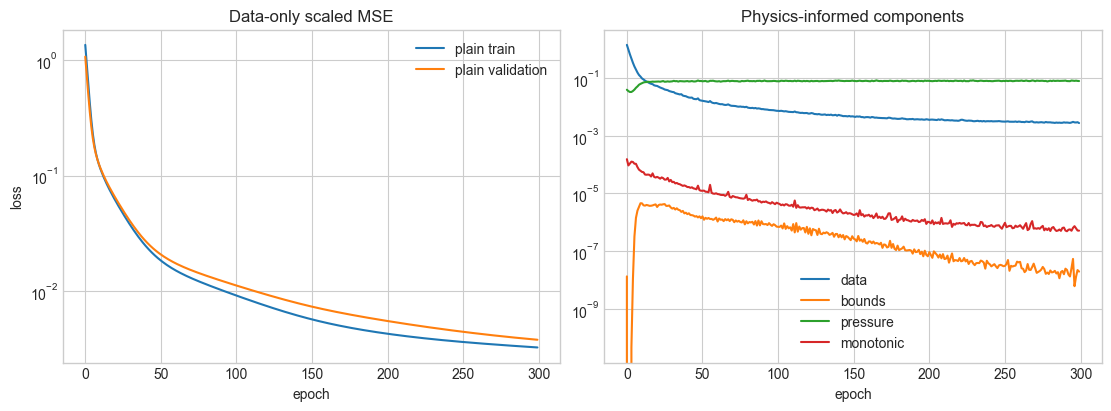

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(plain.trainer.history_.get("loss", []), label="plain train")
if "val_loss" in plain.trainer.history_:
    axes[0].plot(plain.trainer.history_["val_loss"], label="plain validation")
axes[0].set_title("Data-only scaled MSE")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend(frameon=False)

axes[1].plot(physics_history["data_loss"], label="data")
axes[1].plot(physics_history["bounds_loss"], label="bounds")
axes[1].plot(physics_history["pressure_loss"], label="pressure")
axes[1].plot(physics_history["monotonic_loss"], label="monotonic")
axes[1].set_yscale("log")
axes[1].set_title("Physics-informed components")
axes[1].set_xlabel("epoch")
axes[1].legend(frameon=False)
plt.show()

## Accuracy and Physics Comparison

In [9]:
comparison_metrics = pd.concat([plain_metrics, physics_metrics], ignore_index=True)
comparison_physics = pd.DataFrame([
    hydro_physics_report("exact transitions", X_test, y_test),
    hydro_physics_report("plain tanh", X_test, plain.predict(X_test)),
    hydro_physics_report("physics-informed tanh", X_test, physics_network.predict(X_test)),
])

display(comparison_metrics)
display(comparison_physics)

,split,MAE,MSE,RMSE,R2,n_samples
0,plain train,0.026267,0.005274,0.072622,0.995780,1568
1,plain validation,0.029753,0.006596,0.081217,0.994851,336
2,plain test,0.026064,0.005083,0.071293,0.995166,336
3,physics train,0.025221,0.004857,0.069690,0.996114,1568
4,physics validation,0.026647,0.005431,0.073696,0.995760,336
5,physics test,0.025207,0.004952,0.070372,0.995290,336


,model,bounds_rmse,pressure_rmse,monotonic_rmse,max_pressure_violation_bar,max_bound_violation_scaled,physics_score
0,exact transitions,0.000000,0.271084,0.000000,16.216709,0.000000,0.271084
1,plain tanh,0.000139,0.273370,0.000372,16.672549,0.005216,0.273881
2,physics-informed tanh,0.000101,0.271961,0.000460,16.500707,0.004110,0.272522


## Prediction Scatter

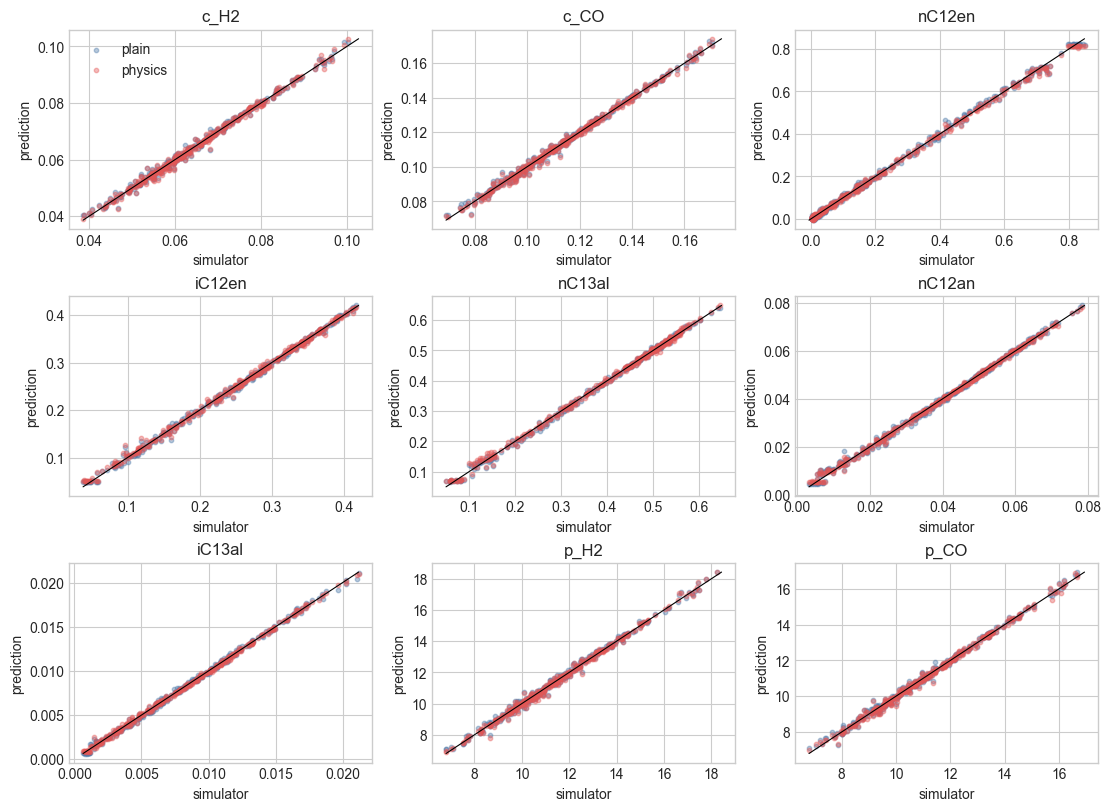

In [10]:
plain_pred = plain.predict(X_test)
physics_pred = physics_network.predict(X_test)
fig, axes = plt.subplots(3, 3, figsize=(11, 8), constrained_layout=True)
for ax, name, j in zip(axes.ravel(), STATE_NAMES, range(len(STATE_NAMES))):
    ax.scatter(y_test[:, j], plain_pred[:, j], s=10, alpha=0.40, label="plain", color="#4c78a8")
    ax.scatter(y_test[:, j], physics_pred[:, j], s=10, alpha=0.40, label="physics", color="#e45756")
    lo = min(y_test[:, j].min(), plain_pred[:, j].min(), physics_pred[:, j].min())
    hi = max(y_test[:, j].max(), plain_pred[:, j].max(), physics_pred[:, j].max())
    ax.plot([lo, hi], [lo, hi], color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("simulator")
    ax.set_ylabel("prediction")
axes.ravel()[0].legend(frameon=False)
plt.show()

## NMPC Optimization Benchmark

The lambda-selected PI model is now compared against the plain tanh transition surrogate in the same coarse receding-horizon PWL-tanh MILP benchmark used by notebook 04. As in notebook 04, this section also attempts a true-plant single-shooting reference: it optimizes the control profile directly against the exact simulator and adds that row to the result table when SciPy is available.


In [11]:
def pressure_backoff_violation(states, times):
    p_total = states[:, IDX["p_H2"]] + states[:, IDX["p_CO"]]
    limit = np.array([20.0 - pressure_backoff(float(t)) for t in times])
    return np.maximum(p_total[1:] - limit[1:], 0.0)


def method_row(label, solution, elapsed, *, status="ok", one_step_mae=np.nan):
    states = solution["states"]
    times = np.asarray(solution.get("times", np.arange(len(states)) * DT_MIN), dtype=float)
    p_total = states[:, IDX["p_H2"]] + states[:, IDX["p_CO"]]
    backoff_violation = pressure_backoff_violation(states, times)
    return {
        "model": label,
        "status": status,
        "terminal nC13al": states[-1, IDX["nC13al"]],
        "max total pressure": float(np.max(p_total)),
        "max backoff violation": float(np.max(backoff_violation)) if backoff_violation.size else 0.0,
        "pressure slack sum": float(np.sum(solution.get("pressure_slacks", np.nan))),
        "closed-loop one-step MAE": one_step_mae,
        "elapsed seconds": elapsed,
    }


def nmpc_row(label, solution, elapsed):
    predicted = solution["predicted"]
    actual = solution["states"][1:]
    return method_row(
        label,
        solution,
        elapsed,
        one_step_mae=float(np.mean(np.abs(predicted - actual))),
    )


def run_true_plant_shooting_benchmark():
    from scipy.optimize import LinearConstraint, minimize

    sim_cache = {}
    plant = HydroformylationParameters()

    def simulate_profile(z):
        key = np.asarray(z, dtype=float).tobytes()
        if key not in sim_cache:
            T_prof, u_prof = z[:N_STEPS], z[N_STEPS:]
            x = INITIAL_STATE.copy()
            traj = [x.copy()]
            for k in range(N_STEPS):
                x = step_state(x, float(T_prof[k]), float(u_prof[k]), DT_MIN, plant)
                traj.append(x.copy())
            if len(sim_cache) > 40000:
                sim_cache.clear()
            sim_cache[key] = np.asarray(traj)
        return sim_cache[key]

    terminal_weight = 500.0
    pressure_weight = 25.0
    backoff_limit = np.array([20.0 - pressure_backoff((k + 1) * DT_MIN) for k in range(N_STEPS)])

    def merit(z):
        traj = simulate_profile(z)
        c_final = traj[-1, IDX["nC13al"]]
        p_total = traj[1:, IDX["p_H2"]] + traj[1:, IDX["p_CO"]]
        pressure_violation = np.maximum(p_total - backoff_limit, 0.0)
        terminal_violation = max(c_final - 0.8, 0.0)
        return -c_final + terminal_weight * terminal_violation**2 + pressure_weight * np.sum(pressure_violation**2)

    rate_A = np.zeros((N_STEPS - 1, 2 * N_STEPS))
    for i in range(1, N_STEPS):
        rate_A[i - 1, i - 1] = -1.0
        rate_A[i - 1, i] = 1.0
    max_jump = DT_RATE_LIMIT * DT_MIN
    rate_constraint = LinearConstraint(rate_A, -max_jump, max_jump)

    z0 = np.r_[np.full(N_STEPS, 378.15), np.full(N_STEPS, 0.008)]
    bounds = [tuple(CONTROL_BOUNDS[0])] * N_STEPS + [tuple(CONTROL_BOUNDS[1])] * N_STEPS
    result = minimize(
        merit,
        z0,
        method="SLSQP",
        bounds=bounds,
        constraints=[rate_constraint],
        options={"maxiter": 250, "ftol": 1e-5, "disp": False},
    )
    traj = simulate_profile(result.x)
    return {
        "times": np.arange(N_STEPS + 1) * DT_MIN,
        "states": traj,
        "controls": np.column_stack([result.x[:N_STEPS], result.x[N_STEPS:]]),
        "scipy_result": result,
    }


nmpc_rows = []
nmpc_solutions = {}

try:
    tic = time.perf_counter()
    shooting_solution = run_true_plant_shooting_benchmark()
    shooting_solution["elapsed"] = time.perf_counter() - tic
    nmpc_solutions["true-plant shooting benchmark"] = shooting_solution
    nmpc_rows.append(method_row("true-plant shooting benchmark", shooting_solution, shooting_solution["elapsed"]))
except Exception as exc:
    nmpc_rows.append({
        "model": "true-plant shooting benchmark",
        "status": "skipped",
        "termination": f"{type(exc).__name__}: {exc}",
        "terminal nC13al": np.nan,
        "max total pressure": np.nan,
        "max backoff violation": np.nan,
        "pressure slack sum": np.nan,
        "closed-loop one-step MAE": np.nan,
        "elapsed seconds": np.nan,
    })

for label, network in [
    ("plain tanh", plain.network),
    ("PI tanh", physics_network),
]:
    try:
        tic = time.perf_counter()
        solution = run_receding_horizon_nmpc(
            network,
            X_train,
            pieces=3,
            penalty=25.0,
            time_limit=15.0,
        )
        elapsed = time.perf_counter() - tic
        nmpc_solutions[label] = solution
        nmpc_rows.append(nmpc_row(label, solution, elapsed))
    except (SolverNotAvailableError, ImportError, RuntimeError, ValueError) as exc:
        nmpc_rows.append({
            "model": label,
            "status": "skipped",
            "termination": f"{type(exc).__name__}: {exc}",
            "terminal nC13al": np.nan,
            "max total pressure": np.nan,
            "max backoff violation": np.nan,
            "pressure slack sum": np.nan,
            "closed-loop one-step MAE": np.nan,
            "elapsed seconds": np.nan,
        })

nmpc_benchmark = pd.DataFrame(nmpc_rows)
nmpc_benchmark


,model,status,terminal nC13al,max total pressure,max backoff violation,pressure slack sum,closed-loop one-step MAE,elapsed seconds
0,true-plant shooting benchmark,ok,0.481527,20.0,0.000091,NaN,NaN,93.972542
1,plain tanh,ok,0.471707,20.0,0.000000,0.0,0.185758,2.909692
2,PI tanh,ok,0.428367,20.0,0.000000,0.0,0.205955,3.740667


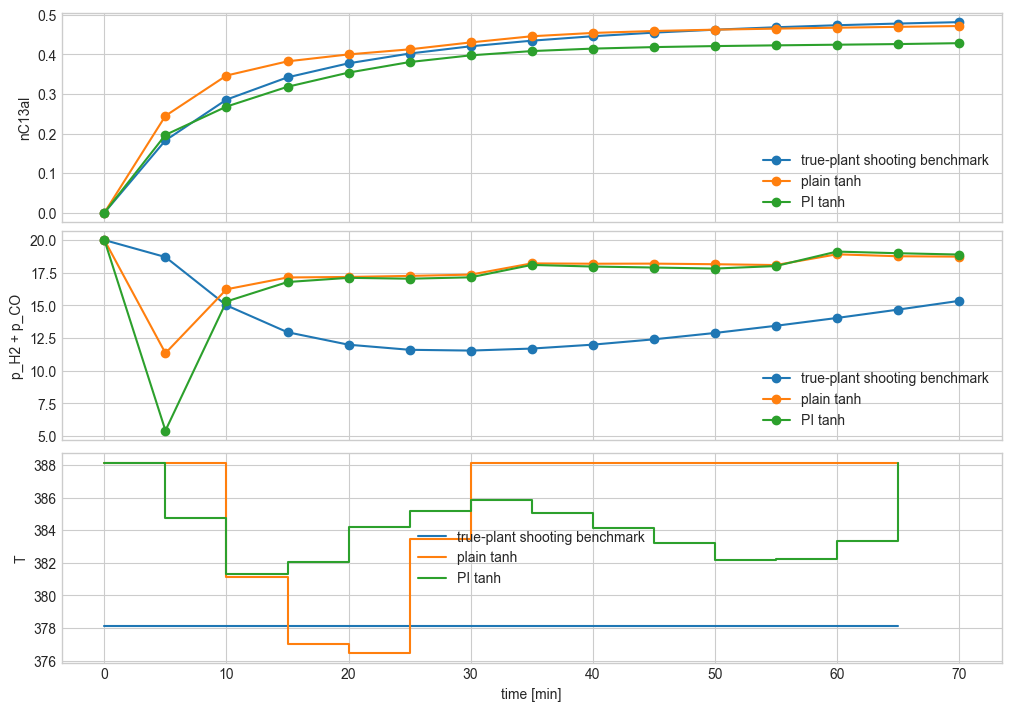

In [12]:
if nmpc_solutions:
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
    for label, solution in nmpc_solutions.items():
        times = solution["times"]
        states = solution["states"]
        controls = solution["controls"]
        axes[0].plot(times, states[:, IDX["nC13al"]], marker="o", label=label)
        axes[1].plot(times, states[:, IDX["p_H2"]] + states[:, IDX["p_CO"]], marker="o", label=label)
        axes[2].step(times[:-1], controls[:, 0], where="post", label=label)
    axes[0].set_ylabel("nC13al")
    axes[1].set_ylabel("p_H2 + p_CO")
    axes[2].set_ylabel("T")
    axes[2].set_xlabel("time [min]")
    for ax in axes:
        ax.legend(frameon=False)
    plt.show()

## Architecture and Solve-Time Comparison

Plain tanh and PI-tanh transition models use the same architecture. This table keeps architecture size visible next to closed-loop NMPC timing so any efficiency difference can be interpreted together with feasibility and terminal product.


In [13]:
def architecture_row(label, network):
    hidden_widths = [layer.weights.shape[1] for layer in network.layers[:-1]]
    return {
        "model": label,
        "inputs": network.n_inputs,
        "outputs": network.n_outputs,
        "hidden layers": len(hidden_widths),
        "hidden widths": hidden_widths,
        "hidden neurons": int(sum(hidden_widths)),
        "parameters": int(sum(layer.weights.size + layer.biases.size for layer in network.layers)),
        "activations": " -> ".join(layer.activation for layer in network.layers),
    }


architecture_comparison = pd.DataFrame([
    architecture_row("plain tanh", plain.network),
    architecture_row("PI tanh", physics_network),
])

nmpc_solve_time_comparison = nmpc_benchmark[
    nmpc_benchmark["model"].isin(["plain tanh", "PI tanh"])
].merge(architecture_comparison, on="model", how="left")

display(architecture_comparison)
display(nmpc_solve_time_comparison[[
    "model",
    "status",
    "hidden neurons",
    "parameters",
    "elapsed seconds",
    "terminal nC13al",
    "max total pressure",
    "max backoff violation",
    "pressure slack sum",
    "closed-loop one-step MAE",
]].reset_index(drop=True))


,model,inputs,outputs,hidden layers,hidden widths,hidden neurons,parameters,activations
0,plain tanh,12,9,1,[32],32,713,tanh -> linear
1,PI tanh,12,9,1,[32],32,713,tanh -> linear


,model,status,hidden neurons,parameters,elapsed seconds,terminal nC13al,max total pressure,max backoff violation,pressure slack sum,closed-loop one-step MAE
0,plain tanh,ok,32,713,2.909692,0.471707,20.0,0.0,0.0,0.185758
1,PI tanh,ok,32,713,3.740667,0.428367,20.0,0.0,0.0,0.205955


## Takeaways

This notebook tunes hydroformylation transition physics weights before running the NMPC optimization benchmark. Useful next checks:

- Refine `LAMBDA_SWEEP_GRID` around the selected `PHYSICS_WEIGHTS` if the validation tradeoff is flat or unstable.
- Compare the selected PI transition model against the 15-second Gurobi MILP path from notebook 04.
- Move `HydroformylationTransitionPhysics` into `src/pwlnet/training/physics_informed.py` after the notebook formulation is stable.